# Module 4 · Simulation accuracy and variance reduction
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **How accurately have we computed a model prediction, and can a better simulation design reach that accuracy with fewer independent runs?**

Guided work: about 40–50 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 2, Part B (week 4)**, completing the lab begun in Module 3. Continue the existing course project.

You will separate Monte Carlo error from model and parameter uncertainty, estimate simulation standard errors, design and verify an importance-sampling estimator, and compare scenarios with common random numbers.

[Course home](../index.html) · [Interactive lesson](../modules/module04.html) · [Project guide](../project-guide.html) · [Data provenance](../data/PROVENANCE.md)

Use **Restart Kernel and Run All** from the course root or `notebooks/`. No download, account, API key, or Python web server is required. Keep exercise answers in your own copy. Browser and Python generators differ; the same integer seed does not produce identical samples across implementations.

## 1. Preserve the model and its fitting boundary
As before, $X_t$ is **completed daily bike rentals** and $Y_t=1\{X_t>4000\}$. Exactly 4,000 rentals is state $0$. The reporting threshold is an assumed scenario, not measured capacity; these data do not measure unmet requests or latent demand.

Fit the row-stochastic matrix $\widehat P$ using only the 242 adjacent pairs wholly within January–August 2011. Rows are origins and columns destinations in order $[0,1]$. September–December has already been examined: it is a **development holdout**, not a pristine final test. All simulation uncertainty below initially conditions on this frozen fitted matrix.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 6231
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

The bundled UCI Bike Sharing observations (Fanaee-T, 2013; [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894), **CC BY 4.0**) contain 365 daily Capital Bikeshare records from Washington, D.C. Read the same local file and verify its provenance hash and calendar before estimating anything.

In [2]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
assert bike["dteday"].tolist() == pd.date_range("2011-01-01", "2011-12-31").tolist()
assert bike["cnt"].notna().all() and bike["cnt"].ge(0).all()
assert np.equal(bike["cnt"], np.floor(bike["cnt"])).all()
THRESHOLD, SPLIT_DATE = 4000, pd.Timestamp("2011-09-01")
bike["y"] = (bike["cnt"] > THRESHOLD).astype(int)

In [3]:
train = bike.loc[bike["dteday"] < SPLIT_DATE].copy()
later = bike.loc[bike["dteday"] >= SPLIT_DATE].copy()
y_train, y_all = train["y"].to_numpy(), bike["y"].to_numpy()
N = np.zeros((2, 2), dtype=int)
np.add.at(N, (y_train[:-1], y_train[1:]), 1)
assert np.array_equal(N, [[114, 20], [19, 89]]) and N.sum() == 242
assert (len(train), len(later)) == (243, 122)
P_hat = N / N.sum(axis=1, keepdims=True)
a, b = P_hat[0, 1], P_hat[1, 0]
display(pd.DataFrame(P_hat, index=["origin 0", "origin 1"], columns=["to 0", "to 1"]))

,to 0,to 1
origin 0,0.850746,0.149254
origin 1,0.175926,0.824074


## 2. Name a quantity whose exact answer can check the simulation
Start in the low state and let $T=\inf\{n\ge1:Y_n=1\}$ be the first high day. Until that first hit, each day remains low with probability $1-a$, where $a=20/134$. Thus $T$ has a geometric distribution on $1,2,\ldots$.

This module estimates a tail event that is **rare under the fitted model**:

$$p=P_0(T>H)=(1-a)^H,\qquad H=30.$$

It asks for **no high day in the next 30 days**, not a low state only on day 30. The second-row parameter $b$ is irrelevant before the first high day. Making the target absorbing is a stopping device; actual rental states can subsequently fall.

The exact answer is available here to reveal implementation errors and study accuracy. For a larger process, an analogous probability may require simulation. These are model-generated paths, not additional observed rentals.

In [4]:
H, REPS, BATCHES = 30, 1000, 400
p = (1 - a) ** H
oracle_crude_se = np.sqrt(p * (1 - p) / REPS)
assert np.isclose(p, 0.007834325094603712)
print(f"Exact model tail P(T>{H}) = {p:.9f}")
print(f"Expected tail events among {REPS} crude runs = {REPS*p:.3f}")
print(f"Exact crude MCSE = {oracle_crude_se:.6f}")

Exact model tail P(T>30) = 0.007834325
Expected tail events among 1000 crude runs = 7.834
Exact crude MCSE = 0.002788


### Independent runs make a simulation standard error possible
Let $Z_r=1\{T_r>H\}$ for independent simulated paths. The crude estimator is

$$\widehat p_R=\frac1R\sum_{r=1}^R Z_r,\qquad E[\widehat p_R]=p,\qquad
\operatorname{Var}(\widehat p_R)=\frac{p(1-p)}R.$$

For general iid contributions with finite variance, estimate the Monte Carlo standard error by

$$\widehat{\operatorname{MCSE}}=s_Z/\sqrt R,\quad
s_Z^2=\frac1{R-1}\sum_r(Z_r-\overline Z)^2.$$

An approximate normal interval is $\overline Z\pm1.96\widehat{\operatorname{MCSE}}$. It is **not an exact 95% interval**. Sparse events or highly variable weights can make it unreliable. Fewer than 10 nonzero or zero contributions is a useful warning flag in these indicator-based examples, not a theorem or a sufficient reliability test; passing that threshold does not guarantee adequate coverage. The single-run summary withholds interval endpoints as `NaN` when this flag is raised, while retaining the sample MCSE as a diagnostic. Repeated-experiment coverage below deliberately evaluates **all raw intervals**, including collapsed zero-event intervals. The independent units are complete simulated runs, not dependent daily states within one path.

Under a fixed finite variance, quadrupling $R$ halves the true MCSE. Unbiasedness does not guarantee small realized error. More simulations reduce numerical uncertainty conditional on $\widehat P$; they do not remove uncertainty in its estimated parameters, fix model misspecification, or add new real data.

In [5]:
def summarize_mc(values):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all():
        raise ValueError("Use at least two finite independent contributions")
    estimate = values.mean()
    se = values.std(ddof=1) / np.sqrt(len(values))
    nonzero = np.count_nonzero(values)
    sparse = min(nonzero, len(values)-nonzero) < 10
    lower, upper = (np.nan, np.nan) if sparse else (estimate-1.96*se, estimate+1.96*se)
    return pd.Series({"estimate": estimate, "estimated MCSE": se,
                      "normal lower": lower, "normal upper": upper})


def crude_samples(reps=REPS, horizon=H, seed=SEED):
    times = np.random.default_rng(seed).geometric(a, size=reps)
    return (times > horizon).astype(float)

In [6]:
crude = crude_samples()
crude_summary = summarize_mc(crude)
assert np.array_equal(crude, crude_samples())
assert set(np.unique(crude)).issubset({0.0, 1.0})
assert abs(crude.mean() - p) < 6 * oracle_crude_se
display(crude_summary.to_frame("crude MC"))
print(f"Tail events observed: {int(crude.sum())}/{REPS}")
print(f"Realized error (known only because p is exact here): {crude.mean()-p:+.6f}")

,crude MC
estimate,0.009000
estimated MCSE,0.002988
normal lower,NaN
normal upper,NaN


Tail events observed: 9/1000
Realized error (known only because p is exact here): +0.001166


**Predict:** If one seed gives an estimate very close to $p$, does that prove the algorithm is more accurate? Change the seed only after recording your prediction.

One realization can look unusually good or bad. The running estimate below uses one reproducible sequence of independent runs. Its pointwise bands are approximate normal intervals at each displayed $R$; they are **not simultaneous bands** over the whole curve. Searching the curve for a pleasing stopping point invalidates a fixed-sample interval interpretation. Choose a run budget or a justified sequential procedure in advance.

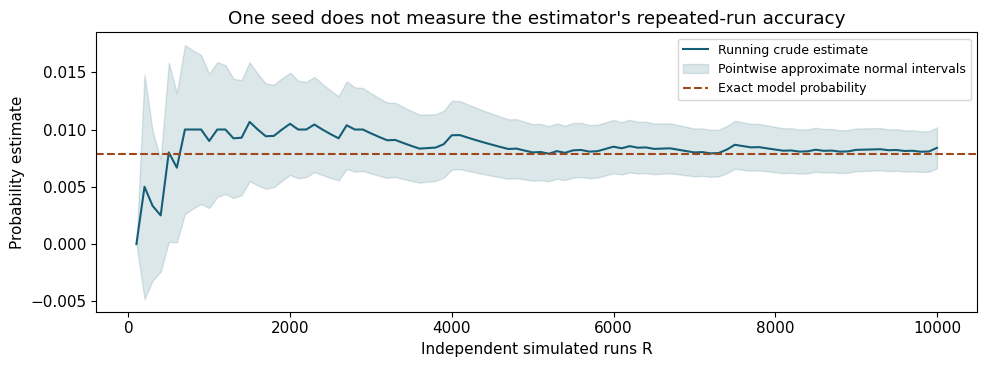

In [7]:
long_crude = crude_samples(reps=10000)
n_grid = np.arange(100, 10001, 100)
running = np.cumsum(long_crude)[n_grid - 1] / n_grid
running_se = np.sqrt(running * (1-running) / (n_grid-1))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(n_grid, running, color="#155e75", label="Running crude estimate")
ax.fill_between(n_grid, running-1.96*running_se, running+1.96*running_se,
                color="#155e75", alpha=0.15, label="Pointwise approximate normal intervals")
ax.axhline(p, color="#a0471c", ls="--", label="Exact model probability")
ax.set(xlabel="Independent simulated runs R", ylabel="Probability estimate",
       title="One seed does not measure the estimator's repeated-run accuracy")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### Repeat the entire experiment to assess numerical accuracy
Run $K=400$ independent experiments at each prespecified budget. Because each contribution is Bernoulli, the number of tail events has the **exact** distribution $M\sim\operatorname{Binomial}(R,p)$. Drawing these counts is a shortcut for repeated independent geometric simulations; it is not a bootstrap of observed bike data.

The empirical root mean squared error, $\sqrt{K^{-1}\sum_k(\widehat p_k-p)^2}$, should be near the exact MCSE. Both its value and empirical coverage vary across batches. Coverage here means the fraction of approximate intervals containing the **known model probability**, not the fraction of real outcomes predicted correctly.

In [8]:
rng_accuracy = np.random.default_rng(SEED + 1)
budgets = np.array([100, 400, 1600, 6400])
accuracy_rows = []
for r in budgets:
    counts = rng_accuracy.binomial(int(r), p, size=BATCHES)
    estimates = counts / r
    se = np.sqrt(estimates * (1-estimates) / (r-1))
    covered = np.abs(estimates-p) <= 1.96*se
    accuracy_rows.append([r, np.sqrt(np.mean((estimates-p)**2)),
        np.sqrt(p*(1-p)/r), covered.mean(), np.mean(counts == 0), (1-p)**r])
accuracy = pd.DataFrame(accuracy_rows, columns=["R", "empirical RMSE", "exact MCSE",
    "normal interval coverage", "observed zero-event rate", "exact zero-event probability"])
display(accuracy.round(6))

,R,empirical RMSE,exact MCSE,normal interval coverage,observed zero-event rate,exact zero-event probability
0,100,0.009018,0.008816,0.5550,0.445,0.455428
1,400,0.004578,0.004408,0.7925,0.065,0.043021
2,1600,0.002236,0.002204,0.9175,0.000,0.000003
3,6400,0.001127,0.001102,0.9450,0.000,0.000000


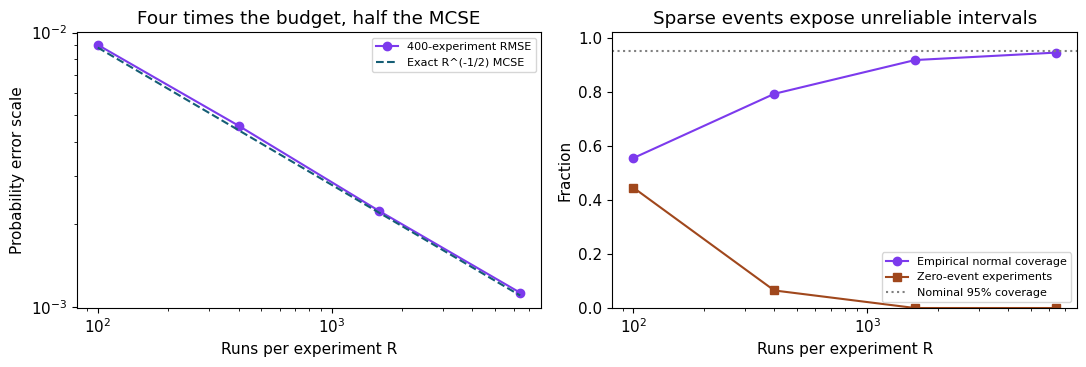

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].loglog(budgets, accuracy["empirical RMSE"], "o-", color="#7c3aed", label="400-experiment RMSE")
axes[0].loglog(budgets, accuracy["exact MCSE"], "--", color="#155e75", label="Exact R^(-1/2) MCSE")
axes[0].set(xlabel="Runs per experiment R", ylabel="Probability error scale", title="Four times the budget, half the MCSE")
axes[1].plot(budgets, accuracy["normal interval coverage"], "o-", color="#7c3aed", label="Empirical normal coverage")
axes[1].plot(budgets, accuracy["observed zero-event rate"], "s-", color="#a0471c", label="Zero-event experiments")
axes[1].axhline(0.95, color="gray", ls=":", label="Nominal 95% coverage")
axes[1].set(xscale="log", xlabel="Runs per experiment R", ylabel="Fraction", ylim=(0, 1.02),
            title="Sparse events expose unreliable intervals")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Zero events do not establish zero probability
If no crude run produces the event, the plug-in sample standard deviation is zero and the normal interval collapses to $[0,0]$. That is a failure of the approximation, not certainty about $p$.

For $R$ independent Bernoulli runs with zero events, an **exact one-sided 95% upper confidence bound** is

$$p_U=1-0.05^{1/R},$$

obtained by solving $(1-p_U)^R=0.05$. This bound concerns a model probability sampled with independent runs; it cannot be applied unchanged to overlapping observed time-series windows or arbitrary importance weights. It is not the usual two-sided 95% interval.

In [10]:
zero_budget = 100
zero_upper = 1 - 0.05 ** (1 / zero_budget)
assert np.isclose((1-zero_upper)**zero_budget, 0.05)
assert summarize_mc(np.zeros(zero_budget))["estimated MCSE"] == 0
print(f"If all {zero_budget} crude contributions are zero:")
print(f"  plug-in normal interval is [0, 0], but exact one-sided upper bound is {zero_upper:.5f}")
print(f"  under this fitted model, P(zero events)={(1-p)**zero_budget:.5f}")

If all 100 crude contributions are zero:
  plug-in normal interval is [0, 0], but exact one-sided upper bound is 0.02951
  under this fitted model, P(zero events)=0.45543


## 3. Importance sampling changes the simulation law and corrects for it
To see long waits more frequently, simulate $T_q\sim\operatorname{Geometric}(q)$ with **proposal hazard $q=0.04$**, smaller than $a$. This is a computational choice, not a refit, policy intervention, or claim about rental behavior.

For target law $f$ and proposal law $g$, the importance-sampling identity is

$$E_f[h(T)]=E_g\!\left[h(T)\frac{f(T)}{g(T)}\right],$$

provided the proposal has positive probability wherever the target integrand is nonzero. Independent weighted contributions need finite variance for the usual MCSE and central-limit approximation. A proposal can increase rather than reduce variance.

Here we retain the path stopped at the first high day or horizon $H$. Outcomes are a hit at $k\le H$ or no hit through $H$. We require $0<q<1$ so every stopped path with positive target probability remains supported.

For a hit at day $k\le H$, the likelihood ratio is

$$w(k)=\left(\frac{1-a}{1-q}\right)^{k-1}\frac aq.$$

For no hit through $H$, it is

$$w(>H)=\left(\frac{1-a}{1-q}\right)^H.$$

Our event is zero on every early-hit path, so the estimator simplifies to

$$Z_q=1\{T_q>H\}\left(\frac{1-a}{1-q}\right)^H,\qquad
\widehat p_{\rm IS}=\frac1R\sum_r Z_{q,r}.$$

The proposal event probability is $r_q=(1-q)^H$, and $r_q\,w(>H)=p$. Average the **weighted contributions**, not unweighted proposal indicators. Do not normalize their sum by the sampled weights: the target is already normalized, and that ratio is a different generally biased estimator. Self-normalized importance sampling has other uses; it is not needed here.

In [11]:
def is_samples(q, reps=REPS, horizon=H, seed=SEED):
    if not 0 < q < 1:
        raise ValueError("Require 0<q<1 to preserve stopped-path support")
    times = np.random.default_rng(seed).geometric(q, size=reps)
    tail = times > horizon
    log_ratio = np.log1p(-a) - np.log1p(-q)
    log_weights = np.where(tail, horizon*log_ratio,
                           (times-1)*log_ratio + np.log(a/q))
    weights = np.exp(log_weights)
    values = np.where(tail, np.exp(horizon*log_ratio), 0.0)
    return values, tail, weights

Q_GOOD = 0.04

In [12]:
is_good, proposal_tail, stopped_weights = is_samples(Q_GOOD)
r_good = (1-Q_GOOD)**H
w_good = ((1-a)/(1-Q_GOOD))**H
assert np.isclose(r_good*w_good, p)
assert np.all(is_good[~proposal_tail] == 0)
assert np.allclose(is_good[proposal_tail], w_good)
assert np.array_equal(is_good, is_samples(Q_GOOD)[0])
display(pd.DataFrame({"crude MC": crude_summary, "importance sampling": summarize_mc(is_good)}))
print(f"Proposal tail fraction={proposal_tail.mean():.4f}; exact proposal probability={r_good:.4f}")
print(f"Each proposal tail contributes weight {w_good:.6f}, not 1.")

,crude MC,importance sampling
estimate,0.009000,0.008291
estimated MCSE,0.002988,0.000390
normal lower,NaN,0.007526
normal upper,NaN,0.009057


Proposal tail fraction=0.3110; exact proposal probability=0.2939
Each proposal tail contributes weight 0.026660, not 1.


### Derive the variance before declaring success
Since $Z_q$ equals $p/r_q$ with probability $r_q$ and zero otherwise,

$$E_g[Z_q]=p,\qquad \operatorname{Var}_g(Z_q)=p^2\left(\frac1{r_q}-1\right).$$

The exact MCSE is $\sqrt{\operatorname{Var}(Z_q)/R}$. Define the **variance reduction factor** as $\operatorname{Var}(Z_{\rm crude})/\operatorname{Var}(Z_q)$ at equal $R$: larger than one favors importance sampling; smaller than one favors crude sampling. At $q=a$, all weights are one and the methods coincide in distribution.

The comparison uses equal numbers of geometric draws. In a simulation that steps through paths, changing the proposal can change path lengths and execution cost. A wall-clock efficiency claim needs measured time as well as variance. Forming log likelihood ratios helps numerics but does not cure inadequate support, huge weights, or floating-point overflow in extreme proposals.

In [13]:
proposal_rows = []
for q in [a, Q_GOOD, 0.30]:
    rq = (1-q)**H
    var_z = p*p*(1/rq-1)
    proposal_rows.append([q, rq, p/rq, np.sqrt(var_z/REPS),
                          p*(1-p)/var_z, (1-rq)**REPS])
proposals = pd.DataFrame(proposal_rows, index=["q=a: crude", "q=.04: helpful", "q=.30: harmful"],
    columns=["proposal q", "proposal tail chance", "tail weight", "exact MCSE",
             "variance reduction factor", "zero-contribution probability"])
assert np.isclose(proposals.iloc[0]["exact MCSE"], oracle_crude_se)
assert np.isclose(proposals.iloc[1]["variance reduction factor"], 52.70202921149104)
display(proposals.round(6))

,proposal q,proposal tail chance,tail weight,exact MCSE,variance reduction factor,zero-contribution probability
q=a: crude,0.149254,0.007834,1.00000,0.002788,1.000000,0.000384
q=.04: helpful,0.040000,0.293858,0.02666,0.000384,52.702029,0.000000
q=.30: harmful,0.300000,0.000023,347.58449,0.052183,0.002855,0.977713


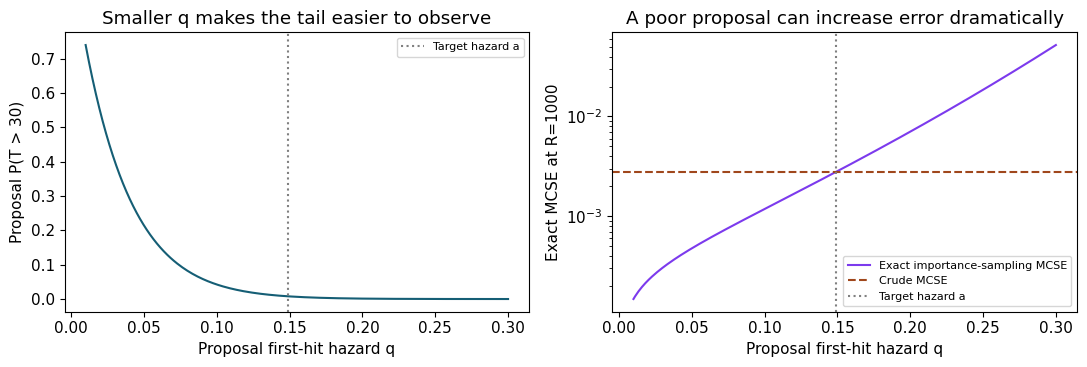

In [14]:
q_grid = np.linspace(0.01, 0.30, 250)
r_grid = (1-q_grid)**H
se_grid = np.sqrt(p*p*(1/r_grid-1)/REPS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(q_grid, r_grid, color="#155e75")
axes[0].set(xlabel="Proposal first-hit hazard q", ylabel="Proposal P(T > 30)",
            title="Smaller q makes the tail easier to observe")
axes[1].semilogy(q_grid, se_grid, color="#7c3aed", label="Exact importance-sampling MCSE")
axes[1].axhline(oracle_crude_se, color="#a0471c", ls="--", label="Crude MCSE")
axes[1].set(xlabel="Proposal first-hit hazard q", ylabel="Exact MCSE at R=1000",
            title="A poor proposal can increase error dramatically")
for ax in axes:
    ax.axvline(a, color="gray", ls=":", label="Target hazard a")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

For $q=.04$, the exact MCSE is about **0.000384**, compared with **0.002788** for crude sampling at $R=1000$: the variance ratio is about **52.70**. The ratio is a theoretical fixed-model result, not a promise that every seed is closer to truth.

For $q=.30$, the proposal makes long waits even rarer. Almost **97.8%** of 1,000-run experiments produce **only zero contributions**; occasional very large weighted observations preserve unbiasedness but make estimation unstable. Most plug-in MCSE values are zero even though the true MCSE is about **0.0522**. An estimator can be unbiased and practically poor.

As $q$ approaches zero in this special tail problem, variance approaches zero because the event is nearly guaranteed under the proposal. Setting $q=0$ is excluded by our full stopped-path support requirement. Exploiting an event-conditioned zero-variance law would already encode the probability we seek here; do not generalize this special algebra into a universal proposal recipe.

In [15]:
rng_methods = np.random.default_rng(SEED + 2)
method_batches, method_rows = {}, []
for name, q in [("Crude", a), ("IS q=.04", Q_GOOD), ("IS q=.30", 0.30)]:
    rq = (1-q)**H
    counts = rng_methods.binomial(REPS, rq, size=BATCHES)
    estimates = counts / REPS * (p/rq)
    se = (p/rq) * np.sqrt((counts/REPS)*(1-counts/REPS)/(REPS-1))
    method_batches[name] = estimates
    method_rows.append([name, estimates.mean(), np.sqrt(np.mean((estimates-p)**2)),
        np.sqrt(p*p*(1/rq-1)/REPS), np.mean(np.abs(estimates-p) <= 1.96*se), np.mean(counts == 0)])
method_report = pd.DataFrame(method_rows, columns=["method", "batch mean", "empirical RMSE",
    "exact MCSE", "normal interval coverage", "zero-contribution fraction"]).set_index("method")

In [16]:
display(method_report.round(6))
assert np.isclose(p*p*(1/(1-a)**H-1), p*(1-p))
assert abs(is_good.mean()-p) < 6*np.sqrt(p*p*(1/r_good-1)/REPS)
print("These 400-experiment diagnostics are random, even with a reproducible seed.")
print("Normal coverage is a diagnostic of interval quality, not a validation of bike behavior.")

,batch mean,empirical RMSE,exact MCSE,normal interval coverage,zero-contribution fraction
method,,,,,
Crude,0.007758,0.002740,0.002788,0.9450,0.0000
IS q=.04,0.007823,0.000382,0.000384,0.9450,0.0000
IS q=.30,0.006952,0.054524,0.052183,0.0175,0.9825


These 400-experiment diagnostics are random, even with a reproducible seed.
Normal coverage is a diagnostic of interval quality, not a validation of bike behavior.


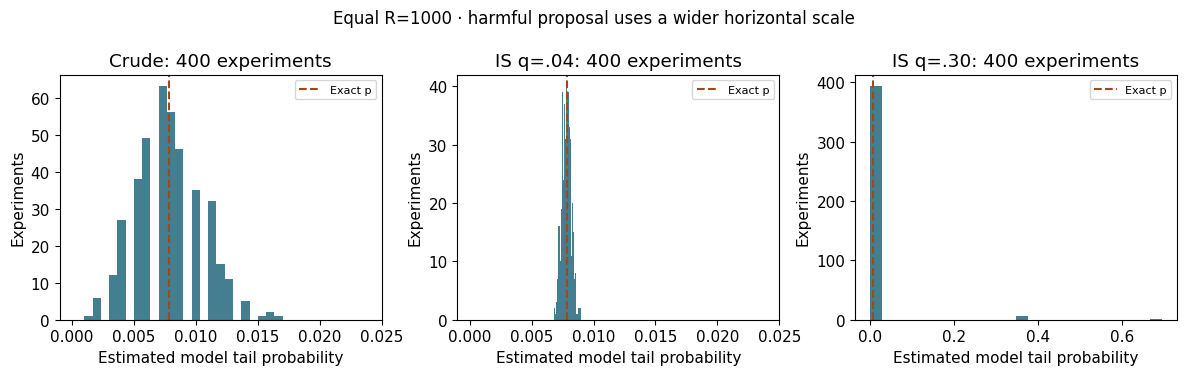

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, estimates) in zip(axes, method_batches.items()):
    ax.hist(estimates, bins=24, color="#155e75", alpha=0.8)
    ax.axvline(p, color="#a0471c", ls="--", label="Exact p")
    ax.set(xlabel="Estimated model tail probability", ylabel="Experiments",
           title=f"{name}: {BATCHES} experiments")
    ax.legend(fontsize=8)
axes[0].set_xlim(-0.001, 0.025)
axes[1].set_xlim(-0.001, 0.025)
fig.suptitle("Equal R=1000 · harmful proposal uses a wider horizontal scale", fontsize=12)
fig.tight_layout()
plt.show()

### Weighted uncertainty belongs to the weighted contributions
For importance sampling, use $s_Z/\sqrt R$ with the actual values $Z_{q,r}$. Using $\sqrt{\widehat p(1-\widehat p)/R}$ treats weighted values as Bernoulli and is generally wrong. The full stopped-path weights should integrate to one under the proposal, but their **sample** average need not equal one.

The identity can be checked exactly by summing the $H$ possible hit outcomes and the tail outcome. This is stronger than requiring a single random estimate to match truth. Then challenge the implementation with $q=a$ and unsupported proposals. A successful run without exceptions is not enough.

In [18]:
for q in [a, Q_GOOD, 0.30]:
    k = np.arange(1, H+1)
    target = np.r_[a*(1-a)**(k-1), (1-a)**H]
    proposal = np.r_[q*(1-q)**(k-1), (1-q)**H]
    weights = target / proposal
    assert np.isclose(proposal @ weights, 1)
    assert np.isclose(proposal[-1]*weights[-1], p)
    if q == a:
        assert np.allclose(weights, 1)
for invalid_q in [0, 1, -0.1, 1.1]:
    try:
        is_samples(invalid_q)
    except ValueError:
        continue
    raise AssertionError("Unsupported proposal was accepted")

## 4. Common random numbers estimate a difference more precisely
A second design targets a **comparison**. Set $H_c=7$ and compare the fitted hazard $a_0=a$ with an **assumed scenario** $a_1=1.25a$. This hypothetical hazard change is not an estimate of a real intervention or a causal effect. The quantity is

$$\Delta=P_{a_1}(T\le7)-P_{a_0}(T\le7).$$

Use the same independent uniform $U_r$ for the two inverse-geometric draws within pair $r$. The scenario hits earlier when $a_1>a_0$, so its hit indicator is at least the baseline indicator. With $D_r=I_{1,r}-I_{0,r}$,

$$\widehat\Delta=\overline D,\qquad
\widehat{\operatorname{MCSE}}=s_D/\sqrt R,$$

$$\operatorname{Var}(I_1-I_0)=\operatorname{Var}(I_1)+\operatorname{Var}(I_0)-2\operatorname{Cov}(I_1,I_0).$$

The positive covariance here reduces variance. Independence is **between pairs**; deliberately paired scenarios are dependent. Common random numbers do not guarantee improvement for every model or output. Pairing must be designed and checked.

In [19]:
H_COMPARE, a0, a1 = 7, a, 1.25*a
p0, p1 = 1-(1-a0)**H_COMPARE, 1-(1-a1)**H_COMPARE
delta = p1-p0
var_paired = delta*(1-delta)
var_independent = p0*(1-p0) + p1*(1-p1)
assert 0 < a0 < a1 < 1
assert np.isclose(delta, 0.0869109049162369)
print(f"Baseline hit chance={p0:.6f}; assumed scenario={p1:.6f}; difference={delta:.6f}")
print(f"Exact MCSE: paired={np.sqrt(var_paired/REPS):.6f}, independent={np.sqrt(var_independent/REPS):.6f}")
print(f"Variance ratio (independent / paired)={var_independent/var_paired:.3f}")

Baseline hit chance=0.677448; assumed scenario=0.764358; difference=0.086911
Exact MCSE: paired=0.008908, independent=0.019966
Variance ratio (independent / paired)=5.023


In [20]:
def inverse_geometric(uniforms, hazard):
    return np.floor(np.log1p(-uniforms) / np.log1p(-hazard)).astype(int) + 1


def compare_scenarios(reps=REPS, paired=True, seed=SEED):
    rng = np.random.default_rng(seed)
    u0 = rng.random(reps)
    u1 = u0 if paired else rng.random(reps)
    hit0 = inverse_geometric(u0, a0) <= H_COMPARE
    hit1 = inverse_geometric(u1, a1) <= H_COMPARE
    return hit1.astype(float)-hit0.astype(float), hit0, hit1

In [21]:
paired, paired0, paired1 = compare_scenarios()
independent, independent0, independent1 = compare_scenarios(paired=False)
assert np.all(paired1 >= paired0)
assert np.array_equal(paired, compare_scenarios()[0])
display(pd.DataFrame({"common random numbers": summarize_mc(paired),
                      "independent scenario streams": summarize_mc(independent)}))
wrong_independent_se = np.sqrt(paired0.var(ddof=1)/REPS + paired1.var(ddof=1)/REPS)
print(f"Paired differences MCSE={paired.std(ddof=1)/np.sqrt(REPS):.6f}")
print(f"Ignoring the pairing would report {wrong_independent_se:.6f}; it omits covariance.")

,common random numbers,independent scenario streams
estimate,0.089000,0.097000
estimated MCSE,0.009009,0.020248
normal lower,0.071343,0.057313
normal upper,0.106657,0.136687


Paired differences MCSE=0.009009
Ignoring the pairing would report 0.020494; it omits covariance.


In [22]:
rng_compare = np.random.default_rng(SEED + 3)
u_shared = rng_compare.random((BATCHES, REPS))
u_separate = rng_compare.random((BATCHES, REPS))
paired_batch = ((u_shared < p1).astype(float)-(u_shared < p0)).mean(axis=1)
independent_batch = ((u_separate < p1).astype(float)-(u_shared < p0)).mean(axis=1)
comparison_report = pd.DataFrame({"paired CRN": [paired_batch.mean(), paired_batch.std(ddof=1),
    np.sqrt(var_paired/REPS)], "independent streams": [independent_batch.mean(),
    independent_batch.std(ddof=1), np.sqrt(var_independent/REPS)]},
    index=["Mean estimated difference", "Empirical between-experiment SD", "Exact MCSE"])
display(comparison_report.round(6))
print("Each method evaluates both scenario outcomes R times; CRN reuses the uniform draws.")

,paired CRN,independent streams
Mean estimated difference,0.086560,0.086048
Empirical between-experiment SD,0.008459,0.019943
Exact MCSE,0.008908,0.019966


Each method evaluates both scenario outcomes R times; CRN reuses the uniform draws.


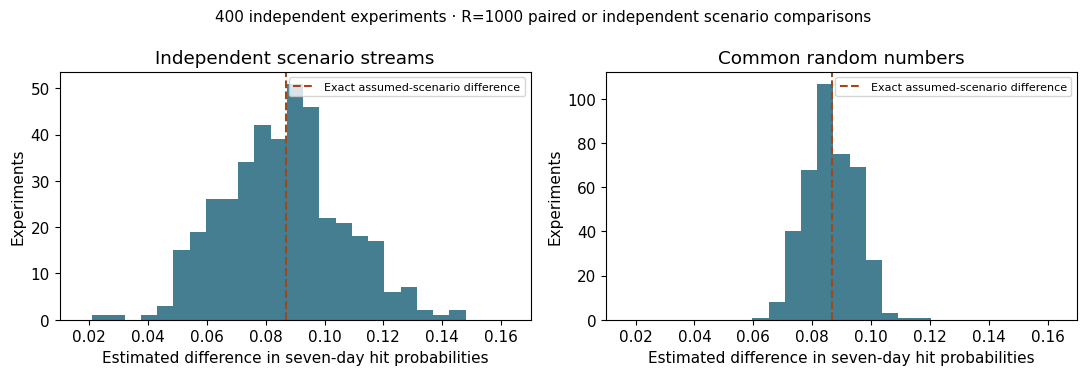

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(0.01, 0.17, 30)
for ax, estimates, title in zip(axes, [independent_batch, paired_batch],
                                ["Independent scenario streams", "Common random numbers"]):
    ax.hist(estimates, bins=bins, color="#155e75", alpha=0.8)
    ax.axvline(delta, color="#a0471c", ls="--", label="Exact assumed-scenario difference")
    ax.set(xlabel="Estimated difference in seven-day hit probabilities", ylabel="Experiments",
           xlim=(0.01, 0.17), title=title)
    ax.legend(fontsize=8)
fig.suptitle("400 independent experiments · R=1000 paired or independent scenario comparisons", fontsize=11)
fig.tight_layout()
plt.show()

## 5. Better simulation does not repair a poorly fitting model
Return to the actual observations, using **30 days** to match the rare-tail simulation target above. This extends the seven-day development diagnostic in Module 3. Candidate origins are August 31 onward; retain state-zero origins only and require all next 30 calendar days to be observed by December 31. August 31 is a high day and is excluded after checking its state.

For each complete window, record **no high day within 30 days**, a first-passage tail event. Also report the earlier seven-day comparison, whose eligible origin set differs. Complete windows remove dataset-end censoring of this finite-horizon outcome; overlapping windows remain dependent. We do not attach an iid standard error to their observed fraction. The model is still frozen at the January–August estimate.

In [24]:
H_OBS = 30
origins = np.arange(len(train)-1, len(bike)-H_OBS)
origins = origins[y_all[origins] == 0]
windows = np.array([y_all[i+1:i+H_OBS+1] for i in origins])
observed_tail = ~windows.any(axis=1)
assert len(origins) == 44 and observed_tail.sum() == 16
assert (origins >= 242).all() and (origins+H_OBS <= 364).all()
assert bike["dteday"].iloc[origins[0]] == pd.Timestamp("2011-09-05")
assert bike["dteday"].iloc[origins[-1]] == pd.Timestamp("2011-12-01")
model_tail_obs = (1-a)**H_OBS
observed_tail_fraction = observed_tail.mean()
precise_mc_obs = crude_samples(reps=64000, horizon=H_OBS, seed=SEED+4)
mc_obs_summary = summarize_mc(precise_mc_obs)

In [25]:
observed_report = pd.Series({"Frozen model exact P(T>30)": model_tail_obs,
    "64,000-run model simulation": precise_mc_obs.mean(),
    "Estimated MCSE of simulation only": mc_obs_summary["estimated MCSE"],
    "Observed dependent-window fraction": observed_tail_fraction})
display(observed_report.to_frame("value").round(6))
origins7 = np.arange(242, len(bike)-7)
origins7 = origins7[y_all[origins7] == 0]
tail7 = np.array([not y_all[i+1:i+8].any() for i in origins7])
assert len(origins7) == 67 and tail7.sum() == 39
print(f"H=30: {observed_tail.sum()}/{len(origins)} tail windows; model={model_tail_obs:.6f}")
print(f"H=7:  {tail7.sum()}/{len(origins7)} tail windows; model={(1-a)**7:.6f}")
print("H30 first/last origin:", bike["dteday"].iloc[origins[[0, -1]]].dt.strftime("%Y-%m-%d").tolist())
assert np.isclose(model_tail_obs, p) and np.isclose(observed_tail_fraction, 16/44)

,value
Frozen model exact P(T>30),0.007834
"64,000-run model simulation",0.007734
Estimated MCSE of simulation only,0.000346
Observed dependent-window fraction,0.363636


H=30: 16/44 tail windows; model=0.007834
H=7:  39/67 tail windows; model=0.322552
H30 first/last origin: ['2011-09-05', '2011-12-01']


At $H=30$, the model tail probability is **0.007834**, while **16/44 = 0.3636** of the observed complete windows contain no high day. For comparison, the earlier $H=7$ values are **0.3226** versus **39/67 = 0.5821**. The two horizons use different origin sets; these are dependent diagnostics, not independent validation samples. The 64,000-run estimate is numerically close to the model prediction, with a small Monte Carlo standard error. That precision cannot bridge a disagreement between the model and observed calendar behavior.

This is a development diagnostic, not proof of a particular causal explanation or a formal significance test. Overlap, parameter estimation, calendar changes, and reuse of the same later period matter. More simulation addresses none of those sources of uncertainty. A revised state definition or model requires substantive justification and appropriately designed further validation.

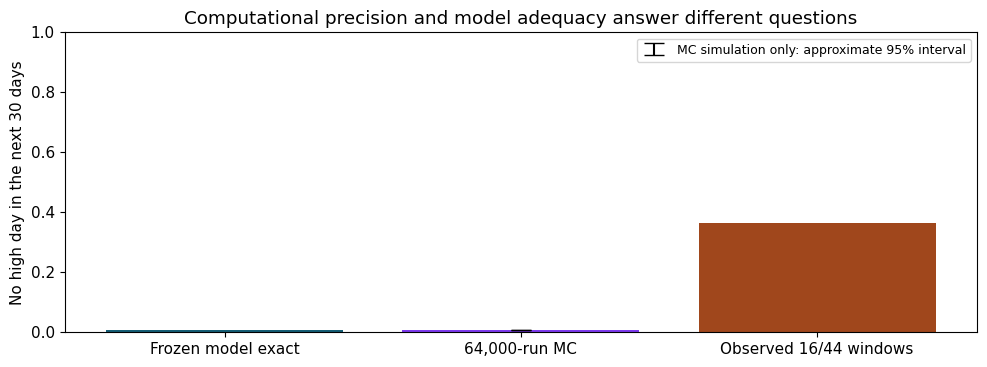

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.8))
values = [model_tail_obs, precise_mc_obs.mean(), observed_tail_fraction]
ax.bar([0, 1, 2], values, color=["#155e75", "#7c3aed", "#a0471c"])
ax.errorbar(1, values[1], yerr=1.96*mc_obs_summary["estimated MCSE"], fmt="none",
            color="black", capsize=7, label="MC simulation only: approximate 95% interval")
ax.set(xticks=[0, 1, 2], xticklabels=["Frozen model exact", "64,000-run MC", "Observed 16/44 windows"],
       ylabel="No high day in the next 30 days", ylim=(0, 1),
       title="Computational precision and model adequacy answer different questions")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 6. Verify an estimator, not just its output
Before accepting code, write its target expectation, the independent replication unit, and any likelihood ratio. Check exact solvable cases, supported proposals, the $q=a$ identity, and chronological data boundaries. Compare empirical repeated-run dispersion with theoretical MCSE where possible; never pick a favorable seed as evidence of correctness.

AI may help propose a sampler or locate a bug. It cannot decide that an unweighted proposal mean estimates the target law, that self-normalization is appropriate, or that daily observations and paired scenarios are independent. Disclose the prompt or tool used, accepted and rejected claims, and your independent checks. AI is optional and earns no credit by itself.

In [27]:
assert np.isclose(np.sqrt(p*(1-p)/(4*REPS)), oracle_crude_se/2)
assert np.isclose((1-Q_GOOD)**H * ((1-a)/(1-Q_GOOD))**H, p)
assert np.isclose(delta, (1-a0)**H_COMPARE-(1-a1)**H_COMPARE)
assert var_paired < var_independent
assert np.array_equal(N, [[114, 20], [19, 89]])  # no refitting after later-data inspection
assert np.array_equal(origins, np.arange(242, 335)[y_all[242:335] == 0])
print("Passed: MCSE scaling, importance weights, paired variance, and frozen-data checks.")

Passed: MCSE scaling, importance weights, paired variance, and frozen-data checks.


## Exercise 1 — Budget and uncertainty (6–8 minutes)
Keep the fitted model, $H=30$, and the exact tail probability defined above.

1. Derive the independent-run budget needed to reduce the **exact crude MCSE to one third** of its value at $R=1000$. Explain why a particular seed need not reduce its realized error by that factor.
2. Repeat 400 independent crude experiments at $R=100$ and $R=900$, using seed 6231 or a recorded seed. Report empirical RMSE, theoretical MCSE, zero-event frequency, and coverage of the stated approximate normal interval.
3. For a zero-event experiment at $R=100$, report the one-sided 95% upper bound. Explain why a zero plug-in MCSE, dependent daily states, and additional real observations are three different issues.

In [28]:
# Your budget derivation, repeated-run diagnostics, and uncertainty interpretation.
pass

## Exercise 2 — Audit an importance-sampling design (6–8 minutes)
Use $H=30$, $R=1000$, seed 6231, and proposals **$q=.06$ and $q=.30$**.

1. Derive the stopped-path likelihood ratio for a hit and for no hit through $H$. Verify that all weighted stopped-outcome probabilities sum to one and that the expected event contribution equals the target probability.
2. For each proposal, report the weighted estimate, estimated MCSE, exact MCSE, variance reduction factor relative to crude sampling, and the exact probability of all-zero contributions. Explain any conflict between estimated and exact MCSE.
3. Identify why unweighted proposal indicators and dividing the weighted event sum by the sampled weight sum do not implement the ordinary estimator taught here. Explain the support issue at $q=1$ and why our full stopped-path sampler also excludes $q=0$.

In [29]:
# Your likelihood derivation, proposal comparison, and support audit.
pass

## Exercise 3 — Preserve pairs when estimating a difference (6–8 minutes)
Set $H_c=7$, baseline $a_0=a$, and the new **assumed scenario** $a_1=1.10a$.

1. Calculate the exact difference in first-hit probabilities. Implement common-random-number and independent-stream comparisons with $R=1000$ and a recorded seed.
2. Report each estimate and its standard error using the sample standard deviation of the run-level differences. Derive the two exact variances and explain the role of covariance.
3. Explain why the pairing used here reduces variance, why common random numbers need not help every model, and why this hypothetical hazard comparison cannot establish an intervention's causal effect.

In [30]:
# Your new scenario comparison, paired uncertainty, and interpretation.
pass

## Exercise 4 — AI audit and real-data boundary (7–10 minutes)
An AI assistant proposes:

```python
estimate = weighted_event.sum() / stopped_weights.sum()  # "ordinary unbiased IS"
se = np.sqrt(estimate * (1-estimate) / R)                 # "weighted MCSE"
# "Fit P on all 365 days for better validation, then simulate until the plot looks stable."
```

1. Explain each problem and repair the estimator, its uncertainty calculation, and the proposed validation/stopping design. Include a discriminating check with $q\ne a$; testing only unit weights is insufficient.
2. Reconstruct the 30-day observed-window tail fraction, reporting origins, no-hit windows, and first/last origin dates. Show that fitting still uses only the 242 within-training transitions and that every selected future window is complete.
3. State what a smaller simulation MCSE would and would not resolve. Explain the limitations from overlapping windows and reuse of the development period. Disclose any AI help and the checks you performed yourself.

In [31]:
# Your repaired estimator, chronology audit, and model-versus-Monte-Carlo interpretation.
pass

## Checkpoint and project connection
Explain, without code, why unbiasedness does not imply a useful estimate; why more simulated paths cannot establish that a fitted model describes real observations; and why the correct standard error depends on the actual independent contributions.

**Complete Concept Lab 2** by combining Module 3's Part A responses with the four short Part B exercise responses, selected output, and a record of verification and any AI use. Keep the course's single project: identify one simulation estimand, a defensible run budget, a candidate variance-reduction design, and a separate check of model adequacy. No additional substantial project is introduced.

The six figures distinguish simulated model behavior from actual observed windows. All uncertainty intervals labeled MC refer only to simulation, conditional on specified parameters. The environment report records the fixed data source and reproducibility settings.

In [32]:
print("Python", platform.python_version())
for package in ["numpy", "pandas", "matplotlib", "nbformat", "nbclient"]:
    print(package, metadata.version(package))
print("Seed:", SEED, "| repeated-experiment batches:", BATCHES)
print("CSV SHA-256:", hashlib.sha256(csv_path.read_bytes()).hexdigest())
print("Completed: MC accuracy, rare-event, importance-sampling, CRN, and data-boundary checks.")

Python 3.10.9
numpy 1.24.2
pandas 2.0.0
matplotlib 3.7.1
nbformat 5.7.0
nbclient 0.5.13
Seed: 6231 | repeated-experiment batches: 400
CSV SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
Completed: MC accuracy, rare-event, importance-sampling, CRN, and data-boundary checks.
